# Сравнение методов персональных top-10 рекомендаций

**Хомяков Владислав Андреевич**

В работе сравниваются ItemKNN, iALS, EASE, факторизационная машина с метаданными и
ALS с собственным целевым сигналом. Эксперимент проведён на подвыборке Amazon
Reviews 2023, категория Video Games. Качество рекомендаций оценено по NDCG@10
и Recall@10 при общем временном разбиении.

## Запуск работы

Ноутбук выполнен в Google Colab на CPU (Python 3.13.16). Для повторения откройте
`experiments.ipynb` в Colab и выполните ячейки сверху вниз. Начальные ячейки создают
рабочую папку `/content/recsys`, записывают те же модули, что находятся в `models/`
и `experiment_utils.py`, и устанавливают закреплённые зависимости. Отдельно загружать
модули в Colab не требуется. Если установка обновила уже импортированные библиотеки,
перезапустите среду и начните выполнение заново.

Исходные отзывы и метаданные автоматически загружаются с Hugging Face по ссылкам
на фиксированную ревизию официального датасета. Требуются доступ к интернету,
около 4 ГБ для исходных данных и среда примерно с 12 ГБ ОЗУ. Данные и временные
артефакты создаются при запуске; в репозиторий они не включены.

Для локального запуска установите зависимости из `requirements.txt` в отдельное
окружение и откройте ноутбук в Jupyter или VS Code с поддержкой Jupyter.
Ядро должно работать в корне репозитория. Команда установки Jupyter зависит от
выбранной среды; Jupyter не требуется для просмотра сохранённых результатов.

Случайное зерно, параметры отбора, сетки поиска и правила оценки заданы в коде.
Фактические версии, границы периодов и контрольные суммы файлов выводятся ниже.
Результаты повторного запуска могут немного различаться между платформами и
версиями вычислительных библиотек; исходный запуск выполнен на CPU.


In [1]:
from pathlib import Path
import os
WORKDIR = Path('/content/recsys') if Path('/content').exists() else Path.cwd()
WORKDIR.mkdir(parents=True, exist_ok=True)
os.chdir(WORKDIR)
Path('models').mkdir(exist_ok=True)
print('Рабочая директория:', Path.cwd())

Рабочая директория: /content/recsys


In [2]:
%%writefile requirements.txt
numpy==2.1.3
scipy==1.16.3
pandas==2.2.3
matplotlib==3.10.0
torch==2.11.0
threadpoolctl==3.7.0
ipython==7.34.0

Writing requirements.txt


In [3]:
%pip -q install -r requirements.txt

In [4]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
import gc, json, random, time, platform, importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import sparse
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
torch.set_num_threads(2)
BLAS_LIMIT = threadpool_limits(limits=2)
CONFIG = {'seed':SEED, 'max_items':6000, 'min_train_history':5,
          'train_fraction':.8, 'validation_end_fraction':.9,
          'relevant_rating':4, 'k':10, 'als_iterations':8, 'fm_epochs':6}
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
versions = {n:importlib.metadata.version(n) for n in
            ['numpy','scipy','pandas','matplotlib','torch','threadpoolctl','ipython']}
print(platform.platform(), platform.python_version())
print('CUDA:',torch.cuda.is_available())
display(pd.Series(versions,name='version').to_frame())
print(json.dumps(CONFIG,indent=2))

Linux-6.6.122+-x86_64-with-glibc2.39 3.13.16
CUDA: False


,version
numpy,2.1.3
scipy,1.16.3
pandas,2.2.3
matplotlib,3.10.0
torch,2.11.0+cpu
threadpoolctl,3.7.0
ipython,7.34.0


{
  "seed": 42,
  "max_items": 6000,
  "min_train_history": 5,
  "train_fraction": 0.8,
  "validation_end_fraction": 0.9,
  "relevant_rating": 4,
  "k": 10,
  "als_iterations": 8,
  "fm_epochs": 6
}


## 1. Постановка задачи и данные

Задача состоит в ранжировании ранее не оценённых товаров для каждого пользователя.
В итоговую выдачу включаются десять товаров с наибольшим score. Релевантным считается
товар, которому пользователь в следующем временном периоде поставил 4 или 5.

Использован [Amazon Reviews 2023](https://amazon-reviews-2023.github.io/), категория
Video Games, из [официального репозитория McAuley Lab](https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023).
Исходный файл содержит **4 624 615 отзывов**, **2 766 656 пользователей** и
**137 249 товаров**. Единица наблюдения — отзыв пользователя о товаре.
Единицей рекомендации выбран `parent_asin`, объединяющий варианты товара.

| Поле источника | Содержание | Поле после загрузки |
|---|---|---|
| `user_id` | ID пользователя | `reviewerID` |
| `parent_asin` | ID товара | `asin` |
| `rating` | Оценка от 1 до 5 | `overall` |
| `timestamp` | Время отзыва, миллисекунды UTC | `unixReviewTime`, секунды UTC |
| `title` | Название товара | `title` |
| `categories` | Путь категорий | `categories` |
| `details.Brand`, `details.Manufacturer`, `store` | Бренд, производитель или магазин | `brand` |

Оценки используются как сигнал предпочтений. Тексты отзывов, цена, средний рейтинг
карточки и связи also-bought в признаки не включены. Названия товаров используются
только при просмотре рекомендаций.

### 1.1. Загрузка и вспомогательные функции

Модуль `experiment_utils.py` содержит загрузчик, подготовку выборки, кодирование
признаков и общий оценщик. Обучение моделей реализовано в отдельных файлах `models/`.

In [5]:
%%writefile experiment_utils.py
"""Data preparation, metadata encoding and common full-catalog evaluation."""
from pathlib import Path
import ast
import gzip
import hashlib
import json
import time
import urllib.request
import numpy as np
import pandas as pd
from scipy import sparse

SOURCE = 'https://amazon-reviews-2023.github.io/'
REVISION = '2b6d039ed471f2ba5fd2acb718bf33b0a7e5598e'
BASE = 'https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/' + REVISION + '/raw/'
URLS = {
    'reviews': BASE+'review_categories/Video_Games.jsonl',
    'metadata': BASE+'meta_categories/meta_Video_Games.jsonl',
}

def download_data(root='data'):
    root = Path(root); root.mkdir(exist_ok=True)
    manifest = {}
    for name, url in URLS.items():
        path = root / url.rsplit('/', 1)[-1]
        if not path.exists():
            print('Download:', url, flush=True)
            temp = path.with_suffix('.part')
            for attempt in range(3):
                try:
                    last_report = [-1]
                    def progress(blocks, block_size, total):
                        mb = blocks * block_size // (64*1024*1024)
                        if mb > last_report[0]:
                            print(name, 'downloaded MB:', blocks*block_size//(1024*1024), flush=True)
                            last_report[0] = mb
                    urllib.request.urlretrieve(url, temp, reporthook=progress)
                    temp.replace(path)
                    break
                except Exception:
                    if attempt == 2: raise
                    time.sleep(2)
        digest = hashlib.sha256()
        with path.open('rb') as f:
            for chunk in iter(lambda: f.read(1024*1024), b''): digest.update(chunk)
        manifest[name] = {'url': url, 'sha256': digest.hexdigest(), 'bytes': path.stat().st_size}
    return root, manifest

def records(path):
    opener = gzip.open if str(path).endswith('.gz') else open
    with opener(path, 'rt', encoding='utf8') as f:
        for line in f:
            try: yield json.loads(line)
            except json.JSONDecodeError: yield ast.literal_eval(line)

def load_reviews(root):
    def rows():
        for j, r in enumerate(records(Path(root)/'Video_Games.jsonl')):
            if j % 500_000 == 0: print('Parsed reviews:', j, flush=True)
            yield {'reviewerID':r.get('user_id'), 'asin':r.get('parent_asin'),
                   'overall':r.get('rating'),
                   'unixReviewTime':None if r.get('timestamp') is None else r['timestamp']//1000}
    return pd.DataFrame(rows())

def prepare(raw, max_items=6000, min_history=5):
    fields = ['reviewerID', 'asin', 'overall', 'unixReviewTime']
    clean = raw.dropna(subset=fields).copy()
    clean = clean[clean.overall.between(1, 5) & (clean.unixReviewTime > 0)]
    clean = clean.sort_values(['unixReviewTime', 'reviewerID', 'asin'], kind='stable')
    clean = clean.drop_duplicates(['reviewerID', 'asin'], keep='first')
    # Boundaries use only timestamps, never future ratings or user activity.
    t1, t2 = np.quantile(clean.unixReviewTime, [.8, .9]).astype(np.int64)
    prefix = clean[clean.unixReviewTime <= t1]
    counts = prefix[prefix.overall >= 4].groupby('asin').size().rename('count').reset_index()
    catalog = counts[counts['count'] >= 5].sort_values(['count','asin'], ascending=[False,True]).head(max_items).asin
    history = prefix[prefix.asin.isin(catalog)]
    users = history.groupby('reviewerID').size()
    active = set(users[users >= min_history].index) & set(history[history.overall >= 4].reviewerID)
    selected = clean[clean.asin.isin(catalog) & clean.reviewerID.isin(active)].copy()
    user_names = sorted(active)
    item_names = sorted(catalog)
    umap, imap = {u:j for j,u in enumerate(user_names)}, {i:j for j,i in enumerate(item_names)}
    selected['u'] = selected.reviewerID.map(umap).astype(int)
    selected['i'] = selected.asin.map(imap).astype(int)
    # Drop catalog items with no observations after user filtering using train alone.
    used = sorted(selected[selected.unixReviewTime <= t1].i.unique())
    selected = selected[selected.i.isin(used)].copy()
    item_names = [item_names[j] for j in used]
    imap = {i:j for j,i in enumerate(item_names)}
    selected['i'] = selected.asin.map(imap).astype(int)
    assert 100_000 <= len(selected) <= 2_000_000, f'Invalid size: {len(selected)}'
    assert len(user_names) >= 1000 and len(item_names) >= 1000
    train = selected[selected.unixReviewTime <= t1].copy()
    val = selected[(selected.unixReviewTime > t1) & (selected.unixReviewTime <= t2)].copy()
    test = selected[selected.unixReviewTime > t2].copy()
    assert train.unixReviewTime.max() < val.unixReviewTime.min()
    assert val.unixReviewTime.max() < test.unixReviewTime.min()
    audit = pd.DataFrame([
        ['source_raw', len(raw),raw.reviewerID.nunique(),raw.asin.nunique()],
        ['clean',len(clean),clean.reviewerID.nunique(),clean.asin.nunique()],
        ['selected',len(selected),len(user_names),len(item_names)],
        ['train',len(train),train.u.nunique(),train.i.nunique()],
        ['validation',len(val),val.u.nunique(),val.i.nunique()],
        ['test',len(test),test.u.nunique(),test.i.nunique()],
    ], columns=['stage','interactions','users','items'])
    split_audit = []
    for label, frame in [('validation',clean[(clean.unixReviewTime>t1)&(clean.unixReviewTime<=t2)]),('test',clean[clean.unixReviewTime>t2])]:
        split_audit.append({'split':label, 'source_events':len(frame),
                            'unknown_user_events':int((~frame.reviewerID.isin(active)).sum()),
                            'outside_catalog_events':int((~frame.asin.isin(item_names)).sum()),
                            'retained_events':len(val if label=='validation' else test)})
    return selected, train, val, test, user_names, item_names, (int(t1),int(t2)), audit, pd.DataFrame(split_audit)

def matrix(frame, shape):
    return sparse.csr_matrix((frame.overall.to_numpy(float),(frame.u,frame.i)),shape=shape)

def load_metadata(root, items):
    wanted = set(items); rows = {}
    for r in records(Path(root)/'meta_Video_Games.jsonl'):
        if r.get('parent_asin') in wanted and r['parent_asin'] not in rows:
            category = r.get('categories') or []
            if category and isinstance(category[0], list): category = category[0]
            rows[r['parent_asin']] = {'asin':r['parent_asin'], 'title':r.get('title') or '',
                'brand':str((r.get('details') or {}).get('Brand') or (r.get('details') or {}).get('Manufacturer') or r.get('store') or ''), 'categories':category}
    return pd.DataFrame([rows.get(i, {'asin':i,'title':'','brand':'','categories':[]}) for i in items])

def encode_metadata(metadata):
    # Each item: own ID, up to two category levels, brand; 0 is padding.
    n = len(metadata); vocabulary = {}; features = np.zeros((n,4),dtype=np.int64)
    features[:,0] = np.arange(1,n+1)
    for i,r in metadata.iterrows():
        cats = [str(x) for x in r.categories if str(x) != 'Video Games'][-2:]
        tokens = ['category:'+x for x in cats] + (['brand:'+r.brand] if r.brand else [])
        for j,token in enumerate(tokens[:3],1):
            if token not in vocabulary: vocabulary[token] = n+len(vocabulary)+1
            features[i,j] = vocabulary[token]
    return features,n+len(vocabulary)

def evaluation_users(heldout, seen, k=10):
    truth = heldout[heldout.overall>=4].groupby('u').i.apply(lambda x:np.array(sorted(set(x)), dtype=int)).to_dict()
    eligible = [u for u in sorted(truth) if seen.shape[1]-seen[u].nnz >= k]
    return np.array(eligible,dtype=int), truth

def recommend(model, users, seen, k=10, batch_size=128):
    result = []
    for start in range(0,len(users),batch_size):
        batch = users[start:start+batch_size]
        scores = np.asarray(model.score(batch), dtype=np.float64)
        assert scores.shape == (len(batch),seen.shape[1]) and np.isfinite(scores).all()
        for j,u in enumerate(batch):
            scores[j,seen[u].indices] = -np.inf
            # Stable sorting breaks ties by ascending catalog index / lexicographic ASIN.
            top = np.argsort(-scores[j],kind='stable')[:k]
            assert np.isfinite(scores[j,top]).all()
            result.append(top)
    return np.asarray(result,dtype=int)

def evaluate(model, users, truth, seen):
    start = time.perf_counter(); recs = recommend(model,users,seen)
    rows = []
    discounts = 1/np.log2(np.arange(2,12))
    for u,top in zip(users,recs):
        relevant = truth[u]
        assert not set(top) & set(seen[u].indices)
        hits = np.isin(top,relevant)
        rows.append((u,float((hits*discounts).sum()/discounts[:min(10,len(relevant))].sum()),float(hits.sum()/len(relevant))))
    per_user = pd.DataFrame(rows,columns=['user','NDCG@10','Recall@10'])
    return {'NDCG@10':per_user['NDCG@10'].mean(),'Recall@10':per_user['Recall@10'].mean(),
            'Coverage@10':len(np.unique(recs))/seen.shape[1], 'recommend_seconds':time.perf_counter()-start}, per_user, recs

def bootstrap_difference(first, second, seed=42, repeats=2000):
    a=first.set_index('user')['NDCG@10']; b=second.set_index('user')['NDCG@10']
    assert a.index.equals(b.index)
    diff=(a-b).to_numpy(); rng=np.random.default_rng(seed)
    samples=np.array([rng.choice(diff,len(diff),replace=True).mean() for _ in range(repeats)])
    return {'mean_difference':diff.mean(),'ci_low':np.quantile(samples,.025),'ci_high':np.quantile(samples,.975)}

Writing experiment_utils.py


In [6]:
from experiment_utils import (download_data, load_reviews, prepare, matrix,
    load_metadata, encode_metadata, evaluation_users, recommend, evaluate,
    bootstrap_difference)

In [7]:
data_root, manifest = download_data()
display(pd.DataFrame(manifest).T)
raw = load_reviews(data_root)
print('Загружено отзывов:',len(raw))
display(raw.head())
display(raw.isna().sum().rename('missing').to_frame())
print('Полных дубликатов:',raw.duplicated().sum())
print('Повторных user-item:',raw.duplicated(['reviewerID','asin']).sum())
print('Пользователей:',raw.reviewerID.nunique(),'товаров:',raw.asin.nunique())

Download: https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/2b6d039ed471f2ba5fd2acb718bf33b0a7e5598e/raw/review_categories/Video_Games.jsonl
reviews downloaded MB: 0
reviews downloaded MB: 64
reviews downloaded MB: 128
reviews downloaded MB: 192
reviews downloaded MB: 256
reviews downloaded MB: 320
reviews downloaded MB: 384
reviews downloaded MB: 448
reviews downloaded MB: 512
reviews downloaded MB: 576
reviews downloaded MB: 640
reviews downloaded MB: 704
reviews downloaded MB: 768
reviews downloaded MB: 832
reviews downloaded MB: 896
reviews downloaded MB: 960
reviews downloaded MB: 1024
reviews downloaded MB: 1088
reviews downloaded MB: 1152
reviews downloaded MB: 1216
reviews downloaded MB: 1280
reviews downloaded MB: 1344
reviews downloaded MB: 1408
reviews downloaded MB: 1472
reviews downloaded MB: 1536
reviews downloaded MB: 1600
reviews downloaded MB: 1664
reviews downloaded MB: 1728
reviews downloaded MB: 1792
reviews downloaded MB: 1856
reviews download

,url,sha256,bytes
reviews,https://huggingface.co/datasets/McAuley-Lab/Am...,7bde9e0a039bdb321e993bfe78a6c7d438fb1504b1ad15...,2682948518
metadata,https://huggingface.co/datasets/McAuley-Lab/Am...,3ad94dfaa8dfed23c5f420aa9ddec415d00f2b8ec9f2d7...,437375785


Parsed reviews: 0
Parsed reviews: 500000
Parsed reviews: 1000000
Parsed reviews: 1500000
Parsed reviews: 2000000
Parsed reviews: 2500000
Parsed reviews: 3000000
Parsed reviews: 3500000
Parsed reviews: 4000000
Parsed reviews: 4500000
Загружено отзывов: 4624615


,reviewerID,asin,overall,unixReviewTime
0,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B07DK1H3H5,4.0,1608186804
1,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B07SRWRH5D,5.0,1587051114
2,AGXVBIUFLFGMVLATYXHJYL4A5Q7Q,B07MFMFW34,5.0,1490877431
3,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,B0BCHWZX95,5.0,1577637634
4,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,B00HUWA45W,5.0,1427591932


,missing
reviewerID,0
asin,0
overall,0
unixReviewTime,0


Полных дубликатов: 53654
Повторных user-item: 69115
Пользователей: 2766656 товаров: 137249


## 2. Исследование и подготовка данных

Проверены пропуски в обязательных полях, повторные записи, распределение оценок,
активность пользователей и популярность товаров. Гистограммы показывают выраженный
длинный хвост: большая часть пользователей оставила мало отзывов, а высокую
активность имеют единичные пользователи. Аналогичная неравномерность наблюдается
по товарам. Поэтому на двух гистограммах использована логарифмическая шкала частот.

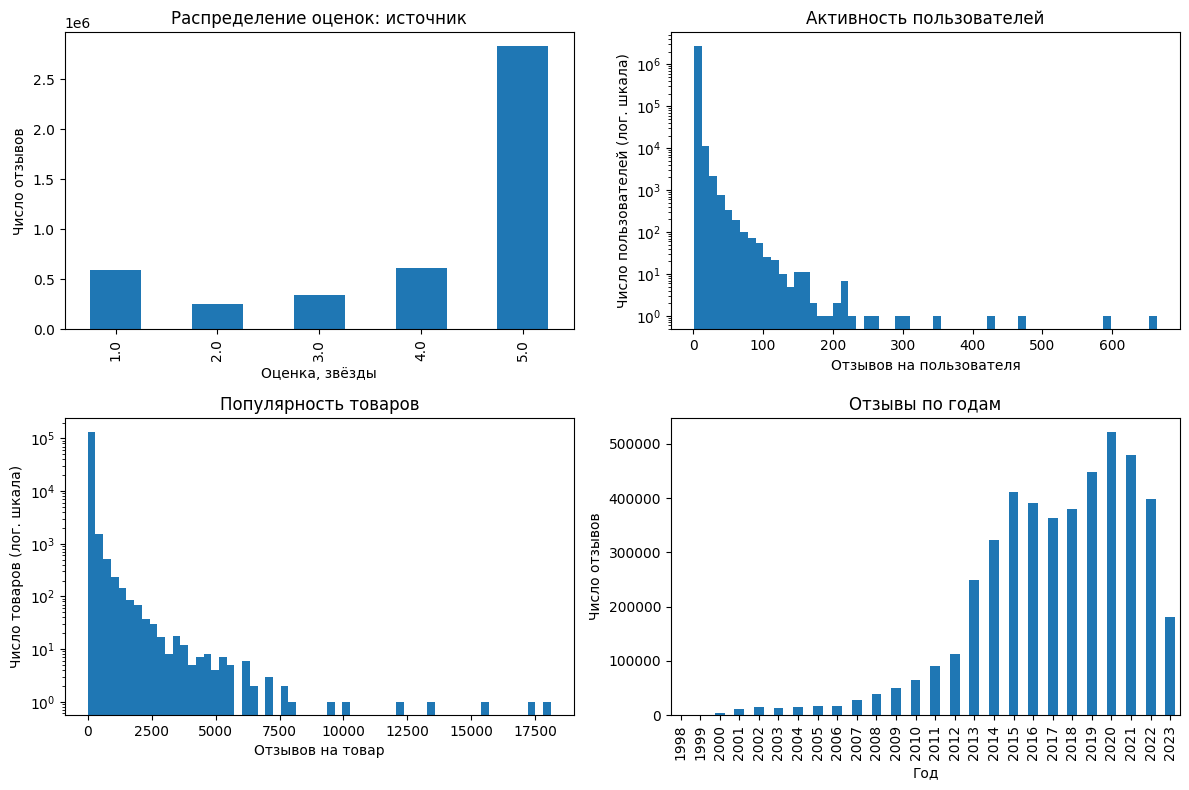

In [43]:
fig,ax=plt.subplots(2,2,figsize=(12,8))
raw.overall.value_counts().sort_index().plot.bar(ax=ax[0,0],title='Распределение оценок: источник')
ax[0,1].hist(raw.groupby('reviewerID').size(),bins=60,log=True); ax[0,1].set_title('Активность пользователей')
ax[1,0].hist(raw.groupby('asin').size(),bins=60,log=True); ax[1,0].set_title('Популярность товаров')
pd.to_datetime(raw.unixReviewTime,unit='s',utc=True).dt.year.value_counts().sort_index().plot.bar(ax=ax[1,1],title='Отзывы по годам')
ax[0,0].set(xlabel='Оценка, звёзды', ylabel='Число отзывов')
ax[0,1].set(xlabel='Отзывов на пользователя', ylabel='Число пользователей (лог. шкала)')
ax[1,0].set(xlabel='Отзывов на товар', ylabel='Число товаров (лог. шкала)')
ax[1,1].set(xlabel='Год', ylabel='Число отзывов')
plt.tight_layout(); plt.show()


### 2.1. Очистка и формирование подвыборки

Строки без ID, оценки или корректного времени исключаются. Допустимый диапазон
оценок — 1–5. Для повторной пары пользователь–товар сохраняется первое взаимодействие.
Это исключает повторное появление товара того же пользователя в разных частях выборки.

Удалено **69 115 повторных записей**; после дедупликации осталось **4 555 500 взаимодействий**.
Для уменьшения вычислительных затрат применён следующий отбор:

1. По времени очищенной категории определены границы 80% и 90% взаимодействий.
2. В train выбраны до 6000 товаров с наибольшим числом положительных отзывов,
   не менее пяти на товар. При равенстве использована сортировка по ASIN.
3. В выбранном каталоге оставлены пользователи с не менее чем пятью train-взаимодействиями
   и хотя бы одной положительной оценкой.
4. Товары, не имеющие train-взаимодействий после отбора пользователей, исключены.
   Полученные списки ID применены к validation и test.

Ограничение каталога связано с EASE: модель хранит плотную матрицу размера
«товар × товар». Низкие оценки сохранены; они используются iALS и FM, а также
учитываются при исключении просмотренных товаров.

Итоговая выборка содержит **429 302 взаимодействия, 51 846 пользователей и 5 974 товара** —
9,28% исходных отзывов. Разреженность матрицы составляет **99,8614%**.
Таким образом, сравнение относится к активным пользователям и ограниченному каталогу.

In [9]:
(selected,train,val,test,user_names,item_names,boundaries,audit,split_audit) = prepare(
    raw,max_items=CONFIG['max_items'],min_history=CONFIG['min_train_history'])
shape=(len(user_names),len(item_names))
print('Границы UTC:',pd.to_datetime(list(boundaries),unit='s',utc=True).tolist())
display(audit); display(split_audit)
print('Разреженность выбранной матрицы:',1-len(selected)/(shape[0]*shape[1]))
print('Разреженность положительной train:',1-(train.overall>=4).sum()/(shape[0]*shape[1]))

Границы UTC: [Timestamp('2021-03-17 03:48:11+0000', tz='UTC'), Timestamp('2022-04-06 04:26:09+0000', tz='UTC')]


,stage,interactions,users,items
0,source_raw,4624615,2766656,137249
1,clean,4555500,2766656,137249
2,selected,429302,51846,5974
3,train,421880,51846,5974
4,validation,5025,3367,1669
5,test,2397,1776,1017


,split,source_events,unknown_user_events,outside_catalog_events,retained_events
0,validation,455550,440625,256514,5025
1,test,455550,444472,332363,2397


Разреженность выбранной матрицы: 0.9986139386995824
Разреженность положительной train: 0.9988735826418847


In [10]:
user_activity = selected.groupby('u').size()
item_popularity = selected.groupby('i').size().sort_values(ascending=False)
summary = pd.DataFrame({
    'user_interactions': user_activity.describe(percentiles=[.5,.9,.99]),
    'item_interactions': item_popularity.describe(percentiles=[.5,.9,.99])})
display(summary)
top_n = max(1, int(np.ceil(.1*len(item_popularity))))
top_share = item_popularity.iloc[:top_n].sum()/len(selected)
print(f'Топ-10% товаров содержат {top_share:.1%} взаимодействий подвыборки.')
print(f'После отбора осталось {len(selected)/len(raw):.1%} исходных отзывов.')
print('Эти описательные показатели не используются для изменения зафиксированного grid.')

,user_interactions,item_interactions
count,51846.000000,5974.000000
mean,8.280330,71.861734
std,6.300526,116.359688
min,5.000000,1.000000
50%,6.000000,38.000000
90%,13.000000,160.000000
99%,33.000000,522.890000
max,235.000000,2060.000000


Топ-10% товаров содержат 45.2% взаимодействий подвыборки.
После отбора осталось 9.3% исходных отзывов.
Эти описательные показатели не используются для изменения зафиксированного grid.


### 2.2. Метаданные товаров

Для FM использованы до двух последних уровней категории и бренд. При отсутствии
бренда последовательно проверяются производитель и магазин. Пропуски сохраняются
и кодируются нулевым padding; взаимодействия из-за отсутствия метаданных не удаляются.

Категории описывают назначение товара, бренд — производителя или продавца. Общие
значения этих признаков позволяют связывать разные товарные ID. Названия в модель
не передаются.

В карточках встречаются названия книг и имена авторов, хотя источник относит их к
Video Games. Следовательно, категоризация содержит шум. История изменения атрибутов
также отсутствует; в эксперименте они рассматриваются как постоянные признаки.

,feature,missing_fraction
0,title,0.000167
1,brand,0.001507
2,categories,0.024607


,asin,title,brand,categories
0,0156031191,Winter's Tale,Mark Helprin (Author),"[Video Games, PC, Games]"
1,0345339258,"Dibs in Search of Self: The Renowned, Deeply M...",Virginia M. Axline (Author),"[Video Games, PC, Games]"
2,0375869026,Wonder,R. J. Palacio (Author),"[Video Games, PC, Games]"
3,0385528191,"The Other Wes Moore: One Name, Two Fates",Wes Moore (Author),"[Video Games, PC, Games]"
4,0399588175,Born a Crime: Stories from a South African Chi...,Trevor Noah (Author),"[Video Games, PC, Games]"


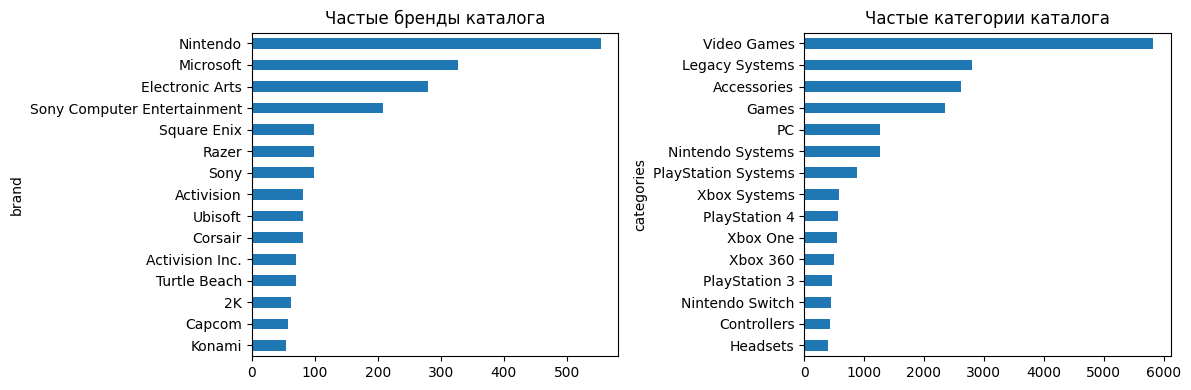

In [11]:
metadata=load_metadata(data_root,item_names)
features,n_features=encode_metadata(metadata)
display(pd.DataFrame({'feature':['title','brand','categories'],
    'missing_fraction':[(metadata.title=='').mean(),(metadata.brand=='').mean(),metadata.categories.map(len).eq(0).mean()]}))
display(metadata.head())
fig,ax=plt.subplots(1,2,figsize=(12,4))
metadata.brand.replace('',pd.NA).value_counts().head(15).sort_values().plot.barh(ax=ax[0],title='Частые бренды каталога')
metadata.categories.explode().value_counts().head(15).sort_values().plot.barh(ax=ax[1],title='Частые категории каталога')
plt.tight_layout();plt.show()

## 3. Протокол оценки

Применено глобальное временное разбиение. Train заканчивается **17.03.2021**, validation —
**06.04.2022**; точные границы UTC приведены в выводе ячейки. Записи с одинаковым
временем не разделяются. После отбора подвыборки доли частей могут отличаться от 80/10/10.

Гиперпараметры выбраны на validation после обучения на train. Для финальной оценки
модели обучены заново на train + validation. Каталог из 5974 товаров зафиксирован
по train. При ранжировании исключаются все ранее оценённые товары, включая оценки 1–3.
Кандидаты не сэмплируются. Равные scores упорядочиваются по ASIN.

Оценка проводится для пользователей с обучающей историей, хотя бы одним доступным
релевантным товаром в будущем периоде и не менее чем десятью непросмотренными
кандидатами. На validation оценены **2602 пользователя**, на test — **1315**.
Состав пользователей и кандидатов одинаков для всех моделей в пределах каждой стадии.

Основная метрика — **NDCG@10**: она учитывает позиции релевантных товаров в выдаче.
Дополнительная метрика — **Recall@10**, доля найденных релевантных товаров.
Для пользователя $u$ с множеством будущих релевантных товаров $G_u$:

$$
Recall@10(u)=\frac{|R_u^{10}\cap G_u|}{|G_u|},
\qquad
NDCG@10(u)=\frac{\sum_{j=1}^{10}\mathbb{1}[i_j\in G_u]/\log_2(j+1)}
{\sum_{j=1}^{\min(10,|G_u|)}1/\log_2(j+1)}.
$$

Метрики усредняются по пользователям. Дополнительно рассчитан Coverage@10 — доля
каталога, появившаяся хотя бы в одной рекомендации.

In [12]:
train_matrix=matrix(train,shape)
trainval=pd.concat([train,val],ignore_index=True)
trainval_matrix=matrix(trainval,shape)
assert len(selected)>=100_000 and min(shape)>=1000
print('Итоговая доля положительных отзывов:',(selected.overall>=4).mean())

Итоговая доля положительных отзывов: 0.8258242449371305


In [13]:
val_users,val_truth=evaluation_users(val,train_matrix)
test_users,test_truth=evaluation_users(test,trainval_matrix)
protocol_counts=pd.DataFrame([
 {'split':'validation','active_users':val.u.nunique(),'users_with_positive':val[val.overall>=4].u.nunique(),'evaluated_users':len(val_users)},
 {'split':'test','active_users':test.u.nunique(),'users_with_positive':test[test.overall>=4].u.nunique(),'evaluated_users':len(test_users)}])
display(protocol_counts)
assert len(val_users)>0 and len(test_users)>0
for users,truth,seen in [(val_users,val_truth,train_matrix),(test_users,test_truth,trainval_matrix)]:
    for u in users:
        assert not set(truth[u]) & set(seen[u].indices)

,split,active_users,users_with_positive,evaluated_users
0,validation,3367,2602,2602
1,test,1776,1315,1315


### 3.1. Проверка оценщика

На контрольном примере проверены значение NDCG@10, Recall@10 и исключение ранее
оценённых товаров. Для kNN, ALS, EASE и FM ниже приведены проверки основных формул
на небольших матрицах.

In [14]:
class FixedScores:
    def score(self,users): return np.tile(np.arange(12,0,-1),(len(users),1))
seen=sparse.csr_matrix(([5.],([0],[0])),shape=(1,12))
stats,_,rec=evaluate(FixedScores(),np.array([0]),{0:np.array([1,3])},seen)
assert list(rec[0])==list(range(1,11))
np.testing.assert_allclose(stats['NDCG@10'],(1+1/np.log2(4))/(1+1/np.log2(3)))
assert stats['Recall@10']==1

print('Проверка метрик и исключения просмотренного пройдена.')

Проверка метрик и исключения просмотренного пройдена.


## 4. Модели и подбор гиперпараметров

Модели реализованы с использованием NumPy, SciPy и PyTorch. Готовые рекомендательные
алгоритмы не применялись. Критерий выбора настроек — максимальный средний NDCG@10
на validation; при равенстве выбирается первая конфигурация сетки.

| Модель | Пространство поиска |
|---|---|
| ItemKNN | Число соседей: 50, 150; shrinkage: 10, 50 |
| iALS и Custom ALS | Размерность: 16, 32; L2: 1, 10; confidence α = 10; 8 итераций |
| EASE | L2: 100, 300, 1000 |
| FM и FM IDs | Пары (размерность, L2): (16, 10⁻⁵), (32, 10⁻⁵), (32, 10⁻⁴) |

Для FM фиксированы learning rate 0,003, batch size 4096, 6 эпох и два дополнительных
негатива на положительный пример. Всего проверена **21 конфигурация**, включая абляцию FM.

In [15]:
als_grid=[{'factors':f,'regularization':r,'alpha':10,'iterations':CONFIG['als_iterations'],'seed':SEED}
          for f in [16,32] for r in [1.,10.]]
fm_grid=[{'factors':f,'regularization':reg,'learning_rate':.003,'epochs':CONFIG['fm_epochs'],'negatives':2,'seed':SEED}
         for f,reg in [(16,1e-5),(32,1e-5),(32,1e-4)]]
GRIDS={
 'ItemKNN':[{'neighbors':k,'shrinkage':s} for k in [50,150] for s in [10,50]],
 'iALS':als_grid,
 'EASE':[{'regularization':r} for r in [100.,300.,1000.]],
 'FM':fm_grid,
 'CustomALS':als_grid,
 'FM IDs':fm_grid,
}
CLASSES={}
validation_rows=[]; best_params={}; best_scores={}

def build_model(name,params):
    if name in ['FM','FM IDs']:
        return FM(features,n_features,metadata=(name=='FM'),**params)
    return CLASSES[name](**params)

def tune_model(name):
    for trial,params in enumerate(GRIDS[name]):
        start=time.perf_counter()
        model=build_model(name,params).fit(train_matrix)
        fit_time=time.perf_counter()-start
        metrics,_,_=evaluate(model,val_users,val_truth,train_matrix)
        validation_rows.append({'model':name,'trial':trial,'params':json.dumps(params,sort_keys=True),
                                'fit_seconds':fit_time,**metrics})
        print(name,trial,'validation NDCG@10 =',round(metrics['NDCG@10'],6),flush=True)
        if name not in best_scores or metrics['NDCG@10']>best_scores[name]:
            best_scores[name]=metrics['NDCG@10'];best_params[name]=params.copy()
        del model;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
        pd.DataFrame(validation_rows).to_csv(ARTIFACTS/'validation_search.csv',index=False)
    rows=pd.DataFrame(validation_rows)
    with pd.option_context('display.max_colwidth',None):
        display(rows[rows.model==name].sort_values('NDCG@10',ascending=False))
    print('Выбрано по validation:',best_params[name])

In [16]:
Path('models/__init__.py').write_text('')

0

### 4.1. ItemKNN

Item-based подход выбран из-за меньшего числа товаров по сравнению с числом пользователей.
Для бинарной матрицы $X_{ui}=\mathbb{1}[r_{ui}\ge4]$ используется сходство

$$
s_{ij}=\frac{X_i^TX_j}{\|X_i\|\|X_j\|+\beta},\qquad s_{ii}=0.
$$

В каждом столбце сохранены $k$ ближайших соседей кандидата. Score равен сумме
сходств с положительными товарами пользователя. Параметр $\beta$ уменьшает влияние
совпадений, поддержанных небольшим числом наблюдений.

In [17]:
%%writefile models/item_knn.py
"""Item cosine kNN, trained from positive implicit interactions."""
import numpy as np
from scipy import sparse

class ItemKNN:
    def __init__(self, neighbors=100, shrinkage=10):
        self.neighbors, self.shrinkage = neighbors, shrinkage

    def fit(self, ratings):
        self.x = (ratings >= 4).astype(np.float64).tocsr()
        counts = np.asarray(self.x.sum(axis=0)).ravel()
        co = (self.x.T @ self.x).tocoo()
        sim = co.data / (np.sqrt(counts[co.row] * counts[co.col]) + self.shrinkage)
        sim[co.row == co.col] = 0
        matrix = sparse.csr_matrix((sim, (co.row, co.col)), shape=co.shape)
        # Keep incoming neighbors: a candidate is scored from its most similar items.
        matrix = matrix.tocsc()
        for col in range(matrix.shape[1]):
            a, b = matrix.indptr[col:col+2]
            if b-a > self.neighbors:
                indices = np.lexsort((matrix.indices[a:b], -matrix.data[a:b]))
                matrix.data[a:b][indices[self.neighbors:]] = 0
        matrix.eliminate_zeros()
        self.weights = matrix.tocsr()
        return self

    def score(self, users):
        return (self.x[users] @ self.weights).toarray()

Writing models/item_knn.py


In [18]:
from models.item_knn import ItemKNN
CLASSES['ItemKNN']=ItemKNN

In [19]:
toy=sparse.csr_matrix(np.array([[5,0,1,0],[4,5,0,0],[0,4,0,5]],float))
x=(toy.toarray()>=4).astype(float)
kn=ItemKNN(neighbors=4,shrinkage=2).fit(toy)
co=x.T@x; norm=np.sqrt(np.diag(co)); expected=co/(norm[:,None]*norm[None,:]+2)
np.fill_diagonal(expected,0)
np.testing.assert_allclose(kn.weights.toarray(),expected,atol=1e-12)
print('Формула сходства проверена на маленькой матрице.')

Формула сходства проверена на маленькой матрице.


In [20]:
display(pd.DataFrame(GRIDS['ItemKNN']))
tune_model('ItemKNN')

,neighbors,shrinkage
0,50,10
1,50,50
2,150,10
3,150,50


ItemKNN 0 validation NDCG@10 = 0.012612
ItemKNN 1 validation NDCG@10 = 0.013223
ItemKNN 2 validation NDCG@10 = 0.01372
ItemKNN 3 validation NDCG@10 = 0.013909


,model,trial,params,fit_seconds,NDCG@10,Recall@10,Coverage@10,recommend_seconds
3,ItemKNN,3,"{""neighbors"": 150, ""shrinkage"": 50}",0.533205,0.013909,0.024895,0.473887,1.664817
2,ItemKNN,2,"{""neighbors"": 150, ""shrinkage"": 10}",0.403614,0.013720,0.025117,0.620522,1.545881
1,ItemKNN,1,"{""neighbors"": 50, ""shrinkage"": 50}",0.417124,0.013223,0.023933,0.498159,1.036879
0,ItemKNN,0,"{""neighbors"": 50, ""shrinkage"": 10}",0.413601,0.012612,0.022681,0.637261,1.046341


Выбрано по validation: {'neighbors': 150, 'shrinkage': 50}


### 4.2. iALS

Бинарный таргет — $p_{ui}=\mathbb{1}[r_{ui}\ge4]$ для наблюдаемых пар, 0 для остальных.
Confidence равен $1+\alpha$ для любой наблюдаемой оценки и 1 для отсутствующей пары.
Поэтому низкая оценка и отсутствие отзыва различаются весом в функции потерь:

$$
\min_{P,Q}\sum_{u,i}c_{ui}(p_{ui}-P_u^TQ_i)^2+
\lambda(\|P\|_F^2+\|Q\|_F^2).
$$

Пользовательские и товарные факторы обновляются поочерёдно. При фиксированном $Q$
обновление пользователя сводится к решению системы:

$$
(Q^TQ+\alpha Q_{I_u}^TQ_{I_u}+\lambda I)P_u
=(1+\alpha)Q_{I_u}^Tp_{u,I_u}.
$$

Матрица $Q^TQ$ рассчитывается один раз на обновление стороны. Явное обращение
матрицы не используется. Регуляризация постоянная, без масштабирования по активности.

In [21]:
%%writefile models/ials.py
"""Weighted regularized matrix factorization with explicit ALS updates."""
import numpy as np
from scipy.linalg import solve

class IALS:
    def __init__(self, factors=32, regularization=10, alpha=10, iterations=10, seed=42):
        self.factors, self.regularization = factors, regularization
        self.alpha, self.iterations, self.seed = alpha, iterations, seed

    def targets(self, values):
        return (values >= 4).astype(np.float64)

    def _update(self, ratings, fixed):
        gram = fixed.T @ fixed + self.regularization * np.eye(self.factors)
        result = np.zeros((ratings.shape[0], self.factors))
        for row in range(ratings.shape[0]):
            a, b = ratings.indptr[row:row+2]
            ids, values = ratings.indices[a:b], ratings.data[a:b]
            if len(ids):
                vectors = fixed[ids]
                lhs = gram + self.alpha * (vectors.T @ vectors)
                rhs = vectors.T @ ((1 + self.alpha) * self.targets(values))
                result[row] = solve(lhs, rhs, assume_a='pos', check_finite=False)
        return result

    def fit(self, ratings):
        rng = np.random.default_rng(self.seed)
        self.items = rng.normal(0, .05, (ratings.shape[1], self.factors))
        transposed = ratings.T.tocsr()
        for _ in range(self.iterations):
            self.users = self._update(ratings, self.items)
            self.items = self._update(transposed, self.users)
        return self

    def score(self, users):
        return self.users[users] @ self.items.T

Writing models/ials.py


In [22]:
from models.ials import IALS
CLASSES['iALS']=IALS

In [23]:
toy=sparse.csr_matrix(np.array([[5,0,1,0],[4,5,0,0],[0,4,0,5]],float))
a=IALS(factors=2,regularization=2,alpha=3,iterations=2,seed=SEED)
fixed=np.array([[.1,.2],[.3,.4],[.2,-.1],[.5,.2]])
updated=a._update(toy,fixed)
for u in range(3):
    ids=toy[u].indices; c=np.ones(4); c[ids]+=3
    p=np.zeros(4); p[ids]=(toy[u].data>=4)
    expected=np.linalg.solve(fixed.T@(c[:,None]*fixed)+2*np.eye(2),fixed.T@(c*p))
    np.testing.assert_allclose(updated[u],expected,atol=1e-12)

print('ALS совпал с прямым решением нормальных уравнений.')

ALS совпал с прямым решением нормальных уравнений.


In [24]:
display(pd.DataFrame(GRIDS['iALS']))
tune_model('iALS')

,factors,regularization,alpha,iterations,seed
0,16,1.0,10,8,42
1,16,10.0,10,8,42
2,32,1.0,10,8,42
3,32,10.0,10,8,42


iALS 0 validation NDCG@10 = 0.014458
iALS 1 validation NDCG@10 = 0.01455
iALS 2 validation NDCG@10 = 0.014249
iALS 3 validation NDCG@10 = 0.014734


,model,trial,params,fit_seconds,NDCG@10,Recall@10,Coverage@10,recommend_seconds
7,iALS,3,"{""alpha"": 10, ""factors"": 32, ""iterations"": 8, ""regularization"": 10.0, ""seed"": 42}",53.959474,0.014734,0.024210,0.101942,2.544407
5,iALS,1,"{""alpha"": 10, ""factors"": 16, ""iterations"": 8, ""regularization"": 10.0, ""seed"": 42}",41.480647,0.014550,0.023575,0.060429,2.714953
4,iALS,0,"{""alpha"": 10, ""factors"": 16, ""iterations"": 8, ""regularization"": 1.0, ""seed"": 42}",41.242650,0.014458,0.023349,0.062270,2.547422
6,iALS,2,"{""alpha"": 10, ""factors"": 32, ""iterations"": 8, ""regularization"": 1.0, ""seed"": 42}",56.406869,0.014249,0.023300,0.104620,2.554051


Выбрано по validation: {'factors': 32, 'regularization': 10.0, 'alpha': 10, 'iterations': 8, 'seed': 42}


### 4.3. EASE

EASE восстанавливает матрицу положительных взаимодействий линейной моделью:

$$
\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\qquad \operatorname{diag}(B)=0.
$$

Для $A=(X^TX+\lambda I)^{-1}$ решение имеет вид $B_{ij}=-A_{ij}/A_{jj}$ при $i\ne j$.
Диагональ $B$ обнулена. Предсказания равны $XB$. Решение вычисляется через разложение
Холецкого; итеративное обучение не требуется.

In [25]:
%%writefile models/ease.py
"""EASE closed-form ridge reconstruction, no pretrained algorithms."""
import numpy as np
from scipy.linalg import cho_factor, cho_solve

class EASE:
    def __init__(self, regularization=300):
        self.regularization = regularization

    def fit(self, ratings):
        self.x = (ratings >= 4).astype(np.float64).tocsr()
        gram = (self.x.T @ self.x).toarray()
        gram.flat[::gram.shape[0]+1] += self.regularization
        inverse = cho_solve(cho_factor(gram), np.eye(gram.shape[0]), check_finite=False)
        self.weights = -inverse / np.diag(inverse)[None, :]
        np.fill_diagonal(self.weights, 0)
        return self

    def score(self, users):
        return self.x[users] @ self.weights

Writing models/ease.py


In [26]:
from models.ease import EASE
CLASSES['EASE']=EASE

In [27]:
e=EASE(regularization=3).fit(toy)
x=(toy.toarray()>=4).astype(float)
pinv=np.linalg.inv(x.T@x+3*np.eye(4)); expected=-pinv/np.diag(pinv);np.fill_diagonal(expected,0)
np.testing.assert_allclose(e.weights,expected,atol=1e-12)

print('EASE: формула весов и нулевая диагональ проверены.')

EASE: формула весов и нулевая диагональ проверены.


In [28]:
display(pd.DataFrame(GRIDS['EASE']))
tune_model('EASE')

,regularization
0,100.0
1,300.0
2,1000.0


EASE 0 validation NDCG@10 = 0.016307
EASE 1 validation NDCG@10 = 0.016424
EASE 2 validation NDCG@10 = 0.016744


,model,trial,params,fit_seconds,NDCG@10,Recall@10,Coverage@10,recommend_seconds
10,EASE,2,"{""regularization"": 1000.0}",18.376374,0.016744,0.031096,0.267995,6.269454
9,EASE,1,"{""regularization"": 300.0}",18.830937,0.016424,0.029776,0.311182,6.064785
8,EASE,0,"{""regularization"": 100.0}",21.706082,0.016307,0.027800,0.367760,5.792181


Выбрано по validation: {'regularization': 1000.0}


### 4.4. Факторизационная машина с метаданными

FM использует user ID, item ID, до двух уровней категории и бренд. Признаки кодируются
как multi-hot; в реализацию передаются индексы активных признаков. Score:

$$
s(x)=b+\sum_jw_jx_j+\frac12\sum_f
\left[\left(\sum_jv_{jf}x_j\right)^2-\sum_jv_{jf}^2x_j^2\right].
$$

Обучение выполняется методом Adam по binary cross-entropy с logits и L2-регуляризацией
активных коэффициентов батча. Оценки 4–5 имеют label 1, оценки 1–3 — label 0.
На каждое положительное взаимодействие добавляются два случайных ненаблюдаемых товара
того же пользователя. Негативы пересэмплируются каждую эпоху; исключается только
обучающая история пользователя. Будущие оценки при сэмплировании не используются.

Все коэффициенты и векторы признаков обучаются с нуля. Для ранжирования применяется
score до sigmoid. Товарная часть FM кэшируется после обучения.

In [29]:
%%writefile models/fm.py
"""Second-order FM with categorical metadata and sampled BCE training."""
import numpy as np
import torch
from torch import nn

class FM:
    def __init__(self, item_features, n_features, factors=32, regularization=1e-5,
                 learning_rate=.003, epochs=8, negatives=2, metadata=True, seed=42):
        self.item_features = np.asarray(item_features, dtype=np.int64)
        self.n_features, self.factors = n_features, factors
        self.regularization, self.learning_rate = regularization, learning_rate
        self.epochs, self.negatives, self.metadata, self.seed = epochs, negatives, metadata, seed

    def fit(self, ratings):
        torch.manual_seed(self.seed)
        rng = np.random.default_rng(self.seed)
        self.n_users, n_items = ratings.shape
        features = self.item_features if self.metadata else self.item_features[:, :1]
        # Feature 0 is padding, users 1..U, catalog features start at U+1.
        catalog = np.where(features > 0, features + self.n_users, 0)
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        embeddings = nn.Embedding(self.n_users+self.n_features+1, self.factors, padding_idx=0).to(device)
        linear = nn.Embedding(self.n_users+self.n_features+1, 1, padding_idx=0).to(device)
        nn.init.normal_(embeddings.weight, std=.03)
        nn.init.zeros_(linear.weight)
        with torch.no_grad(): embeddings.weight[0].zero_()
        bias = nn.Parameter(torch.zeros((), device=device))
        optimizer = torch.optim.Adam([*embeddings.parameters(), *linear.parameters(), bias], lr=self.learning_rate)
        co = ratings.tocoo()
        known = [set(ratings.indices[ratings.indptr[u]:ratings.indptr[u+1]]) for u in range(self.n_users)]
        user_ids, item_ids = co.row.astype(np.int64), co.col.astype(np.int64)
        labels = (co.data >= 4).astype(np.float32)
        catalog_t = torch.tensor(catalog, device=device)
        self.loss_history = []
        for _ in range(self.epochs):
            pos_users = np.repeat(user_ids[labels == 1], self.negatives)
            neg_items = rng.integers(n_items, size=len(pos_users))
            for j, u in enumerate(pos_users):
                while neg_items[j] in known[u]:
                    neg_items[j] = rng.integers(n_items)
            us = np.concatenate([user_ids, pos_users])
            it = np.concatenate([item_ids, neg_items])
            ys = np.concatenate([labels, np.zeros(len(pos_users), dtype=np.float32)])
            order = rng.permutation(len(us)); total = 0.
            for start in range(0, len(us), 4096):
                ix = order[start:start+4096]
                u = torch.as_tensor(us[ix]+1, device=device)
                i = torch.as_tensor(it[ix], device=device)
                ids = torch.cat([u[:, None], catalog_t[i]], dim=1)
                v = embeddings(ids)
                logits = bias + linear(ids).sum((1, 2)) + .5*((v.sum(1)**2-v.square().sum(1)).sum(1))
                target = torch.as_tensor(ys[ix], device=device)
                loss = nn.functional.binary_cross_entropy_with_logits(logits, target)
                loss = loss + self.regularization*(v.square().sum(2).mean()+linear(ids).square().mean())
                optimizer.zero_grad(); loss.backward(); optimizer.step()
                total += loss.item()*len(ix)
            self.loss_history.append(total/len(us))
        with torch.no_grad():
            item_v = embeddings(catalog_t)
            self.items = item_v.sum(1).cpu().numpy()
            self.item_bias = (linear(catalog_t).sum((1,2)) + .5*(item_v.sum(1).square()-item_v.square().sum(1)).sum(1)).cpu().numpy()
            self.users = embeddings.weight[1:self.n_users+1].cpu().numpy().copy()
            self.user_bias = linear.weight[1:self.n_users+1, 0].cpu().numpy().copy()+bias.item()
        return self

    def score(self, users):
        return self.users[users] @ self.items.T + self.item_bias[None, :] + self.user_bias[users, None]

Writing models/fm.py


In [30]:
from models.fm import FM
CLASSES['FM']=FM

In [31]:
# FM inference includes every within-item and user-item pair exactly once.
rng=np.random.default_rng(SEED);v=rng.normal(size=(5,3));w=rng.normal(size=5)
direct=w.sum()+sum(v[j]@v[k] for j in range(5) for k in range(j+1,5))
fast=w[0]+w[1:].sum()+.5*((v[1:].sum(0)**2).sum()-(v[1:]**2).sum())+v[0]@v[1:].sum(0)
np.testing.assert_allclose(direct,fast)
print('Быстрое FM-ранжирование совпало с суммой всех попарных взаимодействий.')

Быстрое FM-ранжирование совпало с суммой всех попарных взаимодействий.


In [32]:
display(pd.DataFrame(GRIDS['FM']))
tune_model('FM')

,factors,regularization,learning_rate,epochs,negatives,seed
0,16,0.00001,0.003,6,2,42
1,32,0.00001,0.003,6,2,42
2,32,0.00010,0.003,6,2,42


FM 0 validation NDCG@10 = 0.009681
FM 1 validation NDCG@10 = 0.008852
FM 2 validation NDCG@10 = 0.008859


,model,trial,params,fit_seconds,NDCG@10,Recall@10,Coverage@10,recommend_seconds
11,FM,0,"{""epochs"": 6, ""factors"": 16, ""learning_rate"": 0.003, ""negatives"": 2, ""regularization"": 1e-05, ""seed"": 42}",41.196331,0.009681,0.017281,0.090224,2.566166
13,FM,2,"{""epochs"": 6, ""factors"": 32, ""learning_rate"": 0.003, ""negatives"": 2, ""regularization"": 0.0001, ""seed"": 42}",55.633020,0.008859,0.014844,0.150653,2.916133
12,FM,1,"{""epochs"": 6, ""factors"": 32, ""learning_rate"": 0.003, ""negatives"": 2, ""regularization"": 1e-05, ""seed"": 42}",57.527628,0.008852,0.014844,0.150988,2.604095


Выбрано по validation: {'factors': 16, 'regularization': 1e-05, 'learning_rate': 0.003, 'epochs': 6, 'negatives': 2, 'seed': 42}


### 4.5. ALS с собственным целевым сигналом

Проверяется гипотеза, что сохранение градаций оценки и отрицательных предпочтений
даёт более информативный сигнал, чем бинарный таргет:

$$
p^{custom}_{ui}=\begin{cases}
(r_{ui}-3)/2,&\text{если оценка наблюдалась},\\
0,&\text{иначе}.
\end{cases}
$$

Оценкам 1–5 соответствуют значения −1, −0,5, 0, 0,5 и 1. Confidence, функция потерь
и ALS-обновления совпадают с базовой моделью. Для проверки влияния таргета
дополнительно проведено сравнение при одинаковых гиперпараметрах.
Критерий релевантности при оценке остался прежним: rating ≥ 4.

In [33]:
%%writefile models/custom_als.py
"""ALS with signed, rating-sensitive target; confidence equals baseline IALS."""
from .ials import IALS

class CustomALS(IALS):
    def targets(self, values):
        return (values - 3.0) / 2.0

Writing models/custom_als.py


In [34]:
from models.custom_als import CustomALS
CLASSES['CustomALS']=CustomALS

In [35]:
np.testing.assert_array_equal(CustomALS().targets(np.arange(1,6)),[-1,-.5,0,.5,1])
print('Таргеты для оценок 1..5:',CustomALS().targets(np.arange(1,6)))

Таргеты для оценок 1..5: [-1.  -0.5  0.   0.5  1. ]


In [36]:
display(pd.DataFrame(GRIDS['CustomALS']))
tune_model('CustomALS')

,factors,regularization,alpha,iterations,seed
0,16,1.0,10,8,42
1,16,10.0,10,8,42
2,32,1.0,10,8,42
3,32,10.0,10,8,42


CustomALS 0 validation NDCG@10 = 0.012956
CustomALS 1 validation NDCG@10 = 0.013116
CustomALS 2 validation NDCG@10 = 0.013743
CustomALS 3 validation NDCG@10 = 0.014061


,model,trial,params,fit_seconds,NDCG@10,Recall@10,Coverage@10,recommend_seconds
17,CustomALS,3,"{""alpha"": 10, ""factors"": 32, ""iterations"": 8, ""regularization"": 10.0, ""seed"": 42}",53.011793,0.014061,0.024065,0.093405,2.586777
16,CustomALS,2,"{""alpha"": 10, ""factors"": 32, ""iterations"": 8, ""regularization"": 1.0, ""seed"": 42}",56.204186,0.013743,0.023681,0.096753,2.539278
15,CustomALS,1,"{""alpha"": 10, ""factors"": 16, ""iterations"": 8, ""regularization"": 10.0, ""seed"": 42}",40.848105,0.013116,0.021772,0.060596,2.713022
14,CustomALS,0,"{""alpha"": 10, ""factors"": 16, ""iterations"": 8, ""regularization"": 1.0, ""seed"": 42}",44.678786,0.012956,0.021451,0.061935,2.558728


Выбрано по validation: {'factors': 32, 'regularization': 10.0, 'alpha': 10, 'iterations': 8, 'seed': 42}


### 4.6. FM без метаданных

Для оценки вклада категорий и бренда обучена FM только с user ID и item ID.
Использованы те же пространство поиска и правило сэмплирования. Дополнительно
рассчитан вариант с настройками, выбранными для FM с метаданными.

In [37]:
tune_model('FM IDs')

FM IDs 0 validation NDCG@10 = 0.010729
FM IDs 1 validation NDCG@10 = 0.009859
FM IDs 2 validation NDCG@10 = 0.009861


,model,trial,params,fit_seconds,NDCG@10,Recall@10,Coverage@10,recommend_seconds
18,FM IDs,0,"{""epochs"": 6, ""factors"": 16, ""learning_rate"": 0.003, ""negatives"": 2, ""regularization"": 1e-05, ""seed"": 42}",28.338864,0.010729,0.018329,0.144292,3.770696
20,FM IDs,2,"{""epochs"": 6, ""factors"": 32, ""learning_rate"": 0.003, ""negatives"": 2, ""regularization"": 0.0001, ""seed"": 42}",41.362568,0.009861,0.018390,0.228323,3.205873
19,FM IDs,1,"{""epochs"": 6, ""factors"": 32, ""learning_rate"": 0.003, ""negatives"": 2, ""regularization"": 1e-05, ""seed"": 42}",41.364314,0.009859,0.018390,0.227988,2.573263


Выбрано по validation: {'factors': 16, 'regularization': 1e-05, 'learning_rate': 0.003, 'epochs': 6, 'negatives': 2, 'seed': 42}


### 4.7. Выбранные параметры

После подбора на validation настройки зафиксированы. Для контрольных сравнений
Custom ALS использует параметры лучшего iALS, а FM IDs — параметры лучшей FM.
В данном запуске независимо выбранные настройки совпали с контрольными,
поэтому строки с суффиксом `matched` в итоговой таблице дублируются.

In [38]:
validation_results=pd.DataFrame(validation_rows)
selected_params_table=pd.DataFrame.from_dict(best_params,orient='index').rename_axis('model')
with pd.option_context('display.max_columns',None):display(selected_params_table)
fixed_params={**best_params,'CustomALS matched':best_params['iALS'].copy(),
             'FM IDs matched':best_params['FM'].copy()}
(ARTIFACTS/'selected_params.json').write_text(json.dumps(fixed_params,indent=2))
print('Настройки зафиксированы. Следующий раздел использует test.')

,neighbors,shrinkage,factors,regularization,alpha,iterations,seed,learning_rate,epochs,negatives
model,,,,,,,,,,
ItemKNN,150.0,50.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
iALS,NaN,NaN,32.0,10.00000,10.0,8.0,42.0,NaN,NaN,NaN
FM,NaN,NaN,16.0,0.00001,NaN,NaN,42.0,0.003,6.0,2.0
CustomALS,NaN,NaN,32.0,10.00000,10.0,8.0,42.0,NaN,NaN,NaN
FM IDs,NaN,NaN,16.0,0.00001,NaN,NaN,42.0,0.003,6.0,2.0
EASE,NaN,NaN,NaN,1000.00000,NaN,NaN,NaN,NaN,NaN,NaN


Настройки зафиксированы. Следующий раздел использует test.


## 5. Результаты на test

Выбранные модели переобучены на train + validation. Все варианты оценены на одном
наборе из 1315 пользователей и общем каталоге. Изменение настроек по test не проводилось.
Время оценки включает вычисление scores, маскирование истории, ранжирование и метрики.

Разница между Custom ALS и iALS, а также между FM и FM IDs оценена парным bootstrap
по пользователям: 2000 повторов, 95% доверительный интервал для разницы NDCG@10.

TEST ItemKNN 0.017809 0.03007
TEST iALS 0.016717 0.029653
TEST EASE 0.020399 0.03353
TEST FM 0.010919 0.018369
TEST CustomALS 0.015323 0.024988
TEST FM IDs 0.013576 0.022263
TEST CustomALS matched 0.015323 0.024988
TEST FM IDs matched 0.013576 0.022263


,model,NDCG@10,Recall@10,Coverage@10,recommend_seconds,fit_seconds,params
0,EASE,0.020399,0.033530,0.217944,4.314282,19.505361,"{""regularization"": 1000.0}"
1,ItemKNN,0.017809,0.030070,0.378306,0.713019,0.571435,"{""neighbors"": 150, ""shrinkage"": 50}"
2,iALS,0.016717,0.029653,0.093405,1.319722,53.331016,"{""alpha"": 10, ""factors"": 32, ""iterations"": 8, ..."
3,CustomALS,0.015323,0.024988,0.088216,1.324890,55.493473,"{""alpha"": 10, ""factors"": 32, ""iterations"": 8, ..."
4,CustomALS matched,0.015323,0.024988,0.088216,1.391068,53.411254,"{""alpha"": 10, ""factors"": 32, ""iterations"": 8, ..."
5,FM IDs,0.013576,0.022263,0.126883,1.320360,31.572137,"{""epochs"": 6, ""factors"": 16, ""learning_rate"": ..."
6,FM IDs matched,0.013576,0.022263,0.126883,1.328366,35.291794,"{""epochs"": 6, ""factors"": 16, ""learning_rate"": ..."
7,FM,0.010919,0.018369,0.081185,1.297542,40.882495,"{""epochs"": 6, ""factors"": 16, ""learning_rate"": ..."


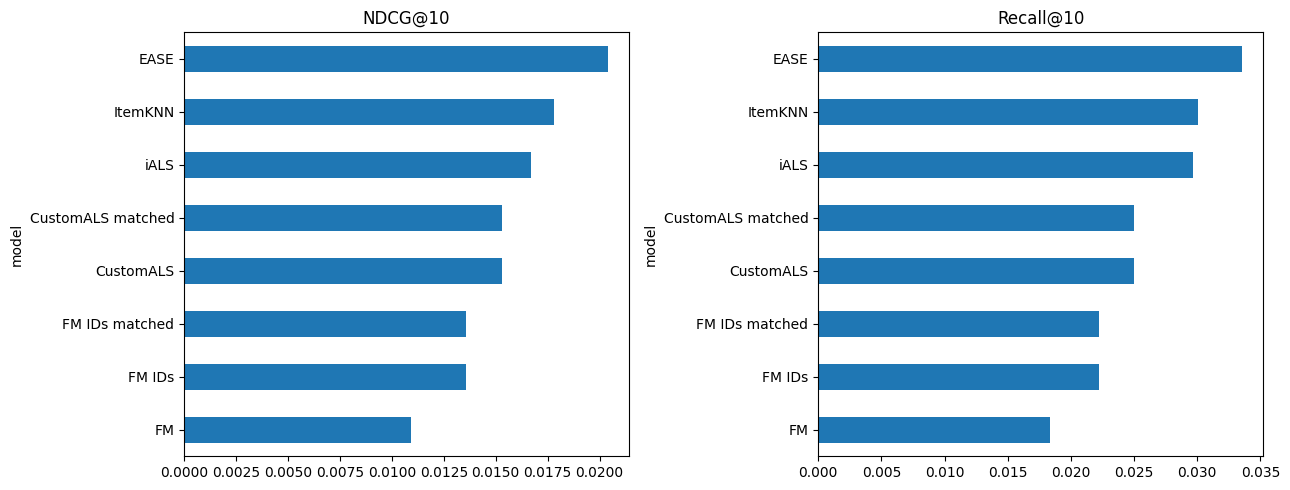

,comparison,mean_difference,ci_low,ci_high
0,"Custom target − binary, identical hyperparameters",-0.001394,-0.004189,0.001285
1,"FM metadata − IDs, identical hyperparameters",-0.002657,-0.007618,0.002198


Парный bootstrap: 2000 выборок пользователей, 95% интервал для разницы NDCG@10.


In [39]:
final_rows=[]; per_user_results={}; recommendations={}
for name,params in fixed_params.items():
    base_name={'CustomALS matched':'CustomALS','FM IDs matched':'FM IDs'}.get(name,name)
    start=time.perf_counter()
    model=build_model(base_name,params).fit(trainval_matrix)
    fit_time=time.perf_counter()-start
    metrics,per_user,recs=evaluate(model,test_users,test_truth,trainval_matrix)
    final_rows.append({'model':name,**metrics,'fit_seconds':fit_time,'params':json.dumps(params,sort_keys=True)})
    per_user_results[name]=per_user;recommendations[name]=recs
    print('TEST',name,round(metrics['NDCG@10'],6),round(metrics['Recall@10'],6),flush=True)
    del model;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
final_results=pd.DataFrame(final_rows).sort_values('NDCG@10',ascending=False).reset_index(drop=True)
display(final_results)
final_results.to_csv(ARTIFACTS/'test_results.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(13,5))
for axis,metric in zip(ax,['NDCG@10','Recall@10']):
    final_results.set_index('model')[metric].sort_values().plot.barh(ax=axis,title=metric)
plt.tight_layout();plt.show()
comparisons=pd.DataFrame([
 {'comparison':'Custom target − binary, identical hyperparameters',**bootstrap_difference(per_user_results['CustomALS matched'],per_user_results['iALS'],SEED)},
 {'comparison':'FM metadata − IDs, identical hyperparameters',**bootstrap_difference(per_user_results['FM'],per_user_results['FM IDs matched'],SEED)}])
display(comparisons)
print('Парный bootstrap: 2000 выборок пользователей, 95% интервал для разницы NDCG@10.')

### 5.1. Сводная таблица

В таблице приведены пять основных моделей и FM IDs. Контрольные варианты `matched`
не повторены, поскольку их настройки и результаты совпали с выбранными версиями.

In [45]:
parameter_names = {
    'neighbors': 'k', 'shrinkage': 'β', 'factors': 'd',
    'regularization': 'λ', 'alpha': 'α',
}
summary_table = final_results[~final_results['model'].str.endswith('matched')].copy()
summary_table['Параметры'] = summary_table['params'].map(
    lambda text: ', '.join(
        f'{parameter_names[key]}={value:g}'
        for key, value in json.loads(text).items() if key in parameter_names
    )
)
summary_table = summary_table.rename(columns={'model': 'Модель'})
summary_table = summary_table[
    ['Модель', 'NDCG@10', 'Recall@10', 'Coverage@10', 'Параметры']
].reset_index(drop=True)
with pd.option_context('display.max_colwidth', None):
    display(summary_table.round(6))


,Модель,NDCG@10,Recall@10,Coverage@10,Параметры
0,EASE,0.020399,0.033530,0.217944,λ=1000
1,ItemKNN,0.017809,0.030070,0.378306,"k=150, β=50"
2,iALS,0.016717,0.029653,0.093405,"α=10, d=32, λ=10"
3,CustomALS,0.015323,0.024988,0.088216,"α=10, d=32, λ=10"
4,FM IDs,0.013576,0.022263,0.126883,"d=16, λ=1e-05"
5,FM,0.010919,0.018369,0.081185,"d=16, λ=1e-05"


### 5.2. Примеры рекомендаций

Приведены выдачи для первых трёх test-пользователей в лексикографическом порядке ID.
Для каждого пользователя показаны пять последних положительных взаимодействий
из истории и top-10 пяти основных моделей. Столбец `relevant_in_test` отмечает товары,
получившие положительную оценку в test-периоде.

In [41]:
main_models=['ItemKNN','iALS','EASE','FM','CustomALS']
for position,u in enumerate(test_users[:3]):
    print('Пользователь:',user_names[u])
    past=trainval[(trainval.u==u)&(trainval.overall>=4)].sort_values('unixReviewTime').tail(5)
    display(pd.DataFrame({'history_asin':[item_names[i] for i in past.i],
                          'title':[metadata.iloc[i].title for i in past.i]}))
    rows=[]
    for name in main_models:
        for rank,i in enumerate(recommendations[name][position],1):
            rows.append({'model':name,'rank':rank,'asin':item_names[i],'title':metadata.iloc[i].title,
                         'relevant_in_test':bool(i in test_truth[u])})
    display(pd.DataFrame(rows))

Пользователь: AE2252DKW4XJIZP5QPFMQVJBVRTA


,history_asin,title
0,B00F27JGVA,PlayStation Vita Memory Card 64GB (PCH-Z641J)
1,B01N6N3J8D,Hard Case for Meta Quest 2 JSVER Carrying Case...
2,B0C5K2TWD8,HyperX Cloud Alpha – Gaming Headset - TimTheTa...


,model,rank,asin,title,relevant_in_test
0,ItemKNN,1,B00PV515DU,Sony PlayStation Vita WiFi,False
1,ItemKNN,2,B0C1W4WV2B,"HyperX Pulsefire FPS Pro - Gaming Mouse, Softw...",False
2,ItemKNN,3,B01GYPAZOK,"(Pack of 2) Screen Protector for PS Vita 2000,...",False
3,ItemKNN,4,B007GYBTGW,Butterfox Double Compartment Carry Case For PS...,False
4,ItemKNN,5,B006JKARP8,PS Vita Portable Charger,False
5,ItemKNN,6,B0BG2DPCKM,Razer DeathAdder V2 Gaming Mouse: 20K DPI Opti...,False
6,ItemKNN,7,B07HC1JR2H,CORSAIR Glaive PRO - RGB Gaming Mouse - Comfor...,False
7,ItemKNN,8,B006PP3YMU,PlayStation Vita USB Cable,False
8,ItemKNN,9,B00G9X4YRM,Nyko Power Grip for PS Vita (PCH-2000),False
9,ItemKNN,10,B006PP404Q,PlayStation Vita Protective Film - Two Pack,False


Пользователь: AE237WVZEGDZD75PG5SPQZILGDDQ


,history_asin,title
0,B004DGIYEG,Alice: Madness Returns - PC
1,B0C7ZTZ5HQ,CHENGDAO Controller for PS3 2 Pack Wireless Co...
2,B0754LGLFP,Redragon K552 Mechanical Gaming Keyboard Rainb...


,model,rank,asin,title,relevant_in_test
0,ItemKNN,1,B0036EWMIK,Castlevania: Lords of Shadow,False
1,ItemKNN,2,B00HTK1NCS,Redragon M601 RGB Gaming Mouse Backlit Wired E...,False
2,ItemKNN,3,B003ZUXQD0,Enslaved: Odyssey To The West - Xbox 360,False
3,ItemKNN,4,B07J27TFCD,Redragon M711 Cobra Gaming Mouse with 16.8 Mil...,False
4,ItemKNN,5,B008B2ZKK4,Castlevania: Lords of Shadow 2 - Playstation 3,False
5,ItemKNN,6,B004CVKGSY,LEGO Pirates of the Caribbean - Xbox 360,False
6,ItemKNN,7,B000G6SPHI,God of War 2 - PlayStation 2,False
7,ItemKNN,8,B004S5MB1O,Shadows of the Damned - Xbox 360,False
8,ItemKNN,9,B003FMTZSI,Spider-Man: Shattered Dimensions - Nintendo Wii,False
9,ItemKNN,10,B002JTX610,Dante's Inferno - Sony PSP,False


Пользователь: AE2FHQDFEPXKMKIZG2T3RDQIOOUA


,history_asin,title
0,B013P0HW7K,Razer Orbweaver Chroma Gaming Keypad: Mechanic...
1,B01IC2A28C,Pokémon Sun and Pokémon Moon Steelbook Dual Pa...
2,B0BDWVBWC9,PowerA Charging Stand for PlayStation 4
3,B077GG9D5D,DualShock 4 Wireless Controller for PlayStatio...


,model,rank,asin,title,relevant_in_test
0,ItemKNN,1,B07PZ8NZSZ,PlayStation 4 Pro 1TB Console,False
1,ItemKNN,2,B01LRLJV28,PlayStation 4 Slim 500GB Console - Uncharted 4...,False
2,ItemKNN,3,B00BGA9X9W,DualShock 4 Wireless Controller for PlayStatio...,False
3,ItemKNN,4,B00HVBPRUO,Gold Wireless Stereo Headset - PlayStation 4,False
4,ItemKNN,5,B00KWOSQC8,Pokémon Alpha Sapphire - Nintendo 3DS,False
5,ItemKNN,6,B004RMK5QG,PlayStation Plus: 12 Month Membership [Digital...,False
6,ItemKNN,7,B00BGA9WK2,PlayStation 4 500GB Console [Old Model][Discon...,False
7,ItemKNN,8,B00KVP76G0,DualShock 4 - White,False
8,ItemKNN,9,B07213YKCX,Pokémon Ultra Sun and Ultra Moon Steelbook Dua...,False
9,ItemKNN,10,B00KVP78FE,DualShock 4 - Camo,False


## 6. Выводы

Наибольшие **NDCG@10 = 0,020399** и **Recall@10 = 0,033530** получены у EASE с
регуляризацией 1000. Следующим по NDCG оказался ItemKNN: 0,017809 при 150 соседях
и shrinkage 50. При этом ItemKNN имеет больший охват каталога — 37,83% против
21,79% у EASE. Лидер по точности и лидер по охвату, таким образом, различаются.

**Кастомный таргет.** При одинаковых настройках (32 фактора, L2 = 10, α = 10)
Custom ALS получил NDCG@10 = 0,015323 против 0,016717 у iALS. Разница составила
−0,001394; 95% bootstrap-интервал — [−0,004189; 0,001285]. Предполагаемое улучшение
от сохранения градаций оценки не подтвердилось; интервал включает ноль.

**Метаданные FM.** FM с категориями и брендом получила NDCG@10 = 0,010919,
FM только с ID — 0,013576. Размерность в обоих случаях равна 16, L2 = 10⁻⁵.
Разница составила −0,002657 с интервалом [−0,007618; 0,002198]. В этом эксперименте
добавление метаданных не улучшило точечную оценку качества. Знак эффекта с учётом
неопределённости не установлен.

Из проверенных конфигураций для данной выборки наиболее удачным оказался EASE.
Для FM и ALS результат ограничен выбранными признаками, сеткой параметров и числом
итераций. Статистическое превосходство EASE над всеми остальными моделями отдельно
не проверялось.

In [46]:
repro = {
    'config': CONFIG,
    'versions': versions,
    'boundaries_utc': list(boundaries),
    'source_files': manifest,
    'selected_params': fixed_params,
    'evaluated_validation_users': len(val_users),
    'evaluated_test_users': len(test_users),
}
_ = (ARTIFACTS / 'reproducibility.json').write_text(json.dumps(repro, indent=2))


### 6.1. Ограничения

- В выборку вошло 9,28% исходных отзывов. Отбор активных пользователей и популярных
  товаров ограничивает переносимость результатов на полный каталог.
- Оценка проведена в warm-start сценарии. Пользователи без истории и товары вне
  train-каталога исключены; на test оценены 1315 из 51 846 пользователей подвыборки.
- Отзывы не содержат истории показов. Ненаблюдаемая пара не является достоверным
  негативом, а положительный отзыв не равнозначен покупке после рекомендации.
- Метаданные представлены одним снимком, содержат пропуски и ошибки категоризации.
  Историческая неизменность атрибутов не проверена.
- Использованы одно временное разбиение, один seed и небольшие сетки параметров.
  Bootstrap учитывает вариативность пользователей, но не разбиений и обучения.
- Неперсонализированный Popularity baseline не оценивался. Поэтому сравнение
  не устанавливает преимущество персонализации над общей выдачей популярных товаров.

## 7. Источники

1. McAuley Lab. [Amazon Reviews 2023: описание и загрузка данных](https://amazon-reviews-2023.github.io/).
2. Hu, Y., Koren, Y., Volinsky, C. [Collaborative Filtering for Implicit Feedback Datasets](https://doi.org/10.1109/ICDM.2008.22). ICDM, 2008.
3. Steck, H. [Embarrassingly Shallow Autoencoders for Sparse Data](https://doi.org/10.1145/3308558.3313710). WWW, 2019.
4. Rendle, S. [Factorization Machines](https://doi.org/10.1109/ICDM.2010.127). ICDM, 2010.
5. Hou, Y. et al. [Bridging Language and Items for Retrieval and Recommendation](https://arxiv.org/abs/2403.03952). 2024.